# Defense evaluation: Dummy Actuations

* load pretrained DRQN attack agent
* generate a true protocol
* search a Pareto front of defenses for it (`run_defense.py`)
* pick a defense schedule from the saved front
* run multipass refinement with the attack agent, once undefended and once with the defense's dummy actuations active

**necessary imports:**

In [21]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))                     # repo root: defense.NSGA_II_utils.*
sys.path.insert(0, os.path.abspath('../environment_utils'))   # Env, CustomFeatureExtractor, helper_functions, protocol_creation
sys.path.insert(0, os.path.abspath('./RL_agent_utils'))       # attack_agent, multipass_refinement, plot_3d

import gymnasium as gym
import numpy as np
import run_defense
from attack_agent import DRQNagent
from belief_state import BeliefStateMap
from CustomFeatureExtractor import CustomFeatureExtractor
from Env import VoltageDistributionEnv
from multipass_refinement import MultipassEnvWrapper, PassBasedMasking, extract_qvalues
from plot_3d_entropy import plot_3d_entropy_path
from protocol_creation import intelligent_walk

import defense.NSGA_II_utils.config as config
import defense.NSGA_II_utils.evolve as evolve
import defense.NSGA_II_utils.field as field
import defense.NSGA_II_utils.genome as genome
import defense.NSGA_II_utils.visualize as visualize


## 1. Load pretrained attack agent (no training)

In [22]:
loaded_agent = DRQNagent.load_complete(
    '../models/RecurrentDQN_Finalized_SCIBOT_V1.pkl',  
    env_constructor=lambda: VoltageDistributionEnv(),
    feature_extractor_constructor=lambda obs_space: CustomFeatureExtractor(obs_space)
)

Complete agent loaded from: ../models/RecurrentDQN_Finalized_SCIBOT_V1.pkl
Trained for 100015 steps, 2239 episodes


## 2. Generate droplet protocol

In [29]:
protocol = [ tuple(cell) for cell in intelligent_walk(config.OBSTACLES, config.VISIT_POINTS, config.RESERVOIRS, config.GRID_SIZE)]
print(f"protocol: {len(protocol)} timesteps, {protocol[0]} -> {protocol[-1]}")

protocol: 42 timesteps, (2, 2) -> (6, 15)


## 3. Search the Pareto front of defenses for this protocol

Same `run_defense.py` used from the command line, just handed our protocol instead of a random one.
Saves `last_run.npz` and `pareto_front.csv`, same as the CLI.

In [30]:
protocol_args = ' '.join(str(v) for cell in protocol for v in cell)
!python3 run_defense.py --protocol {protocol_args}

protocol: 42 timesteps, (2, 2) to (6, 15)
searching (pop 1000, 50 generations)...

search took 161.5s
population 1000 -> 1000 non-dominated (Pareto-optimal) out of it
saved last_run.npz, pareto_front.csv

all 3 columns are [0,1], lower is better on every one
                      min   median      max
           count    0.038    0.506    0.976
          spread    0.001    0.031    0.069
 attack_accuracy    0.175    0.456    1.000

full table in pareto_front.csv; run `python run_defense.py --pick <index>` to render one
opening interactive 3D plot (close the window to exit)...
Figure(800x700)


since jupyternotebook is weird about showing plots (can't open a subfigure), run the cell above and then run the following commands in the terminal (make sure you are in defense folder `cd defense`). 
* `python3 run_defense.py --front`
* `python3 run_defense.py --pick 1`, can exchange 1 with index of choice. 


## 4. Visualize Pareto front of defenses

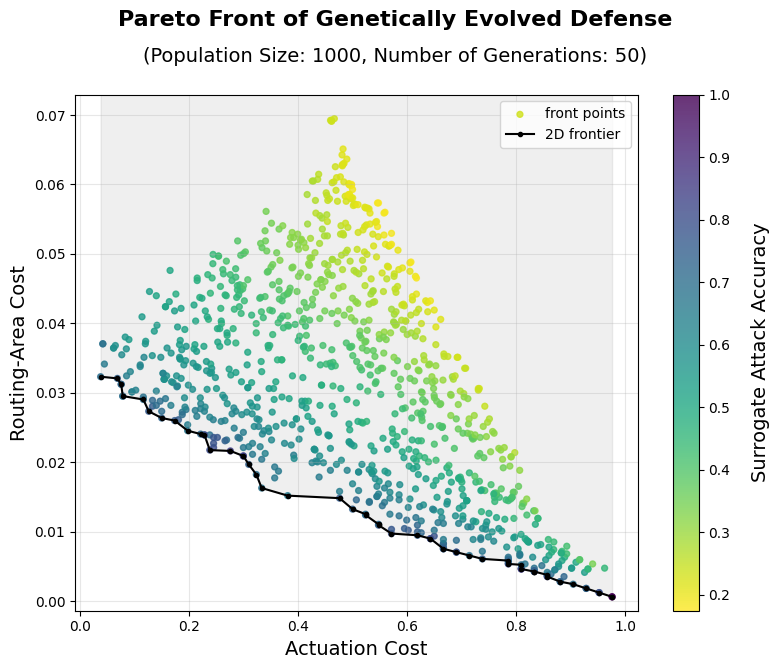

In [31]:
_, X, F = evolve.load_run('last_run.npz')
visualize.plot_pareto_slice(F, config.POP_SIZE, config.N_GEN)

## 5. Check Defense against RL agent 

Pick an index off the front above, decode it into a schedule, and run the agent through 3 passes of the same protocol. 

Alongside the agent's own belief, a second "ground-truth" belief is tracked: every probe is fed `real_field(true_droplet)[probe]`, so the real droplet's own EMF at that electrode, regardless of any
dummy contribution mixed into what the agent actually saw. 

In [32]:
class DefenseMultipassEnvWrapper(MultipassEnvWrapper):
    """
    Same 3-pass refinement as MultipassEnvWrapper, but every pass uses our fixed protocol and injects the schedule's combined real+dummy EMF into what the agent actually observes.
    """

    def __init__(self, env, pass_based_masking, pass_num, schedule, protocol):
        super().__init__(env, pass_based_masking, pass_num, stored_protocol=protocol)
        self.schedule = schedule
        self.ground_truth_belief = BeliefStateMap(env.size, env.belief.sigma, env.belief.threshold)
        self.ground_truth_entropy = []

    def _apply_defense(self):
        """
        Overwrite the env's voltage grid for the current droplet position with the combined (real+dummy) field, so the next measurement reflects the defense.
        """
        t = self.env._droplet_path_index
        true_cell = tuple(self.env._droplet_location)
        dummies = self.schedule[t] if t < len(self.schedule) else []
        self.env._voltage_grid = field.combined_field(true_cell, dummies)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)

        self.env._droplet_path = self.stored_protocol
        self.env._droplet_path_index = 0
        self.env._droplet_location = self.env._droplet_path[0]
        self.env.end_pos = self.env._droplet_path[-1]
        self.env.length = len(self.env._droplet_path)
        self._apply_defense()

        if self.pass_num > 1:
            refined_mask = self.pass_based_masking.get_refined_mask(timestep=0, current_belief_mask=info['action_mask'])
            info['action_mask'] = refined_mask

        self.timestep = 0
        self.pass_based_masking.start_new_episode()

        self.ground_truth_belief.reset()
        self.ground_truth_entropy = []

        return obs, info

    def step(self, action):
        t = self.timestep
        true_cell = tuple(self.env._droplet_location)  # droplet's position for timestep t, before it advances

        obs, reward, terminated, truncated, info = super().step(action)

        probe = (action // self.grid_size, action % self.grid_size)
        measurement = field.real_field(true_cell)[probe]
        self.ground_truth_belief.prediction()
        self.ground_truth_belief.correction(measurement=measurement, probe_position=probe)
        self.ground_truth_entropy.append(self.ground_truth_belief.get_state_entropy())

        self._apply_defense()  # prep the next timestep's combined field before the next step() call
        return obs, reward, terminated, truncated, info

In [33]:
def run_defense_multipass(agent, protocol, schedule, num_passes=3):
    """
    Same 3-pass loop as run_multipass_protocol, but through DefenseMultipassEnvWrapper
    """
    pass_based_masking = PassBasedMasking(config.GRID_SIZE)
    ground_truth_entropy = {}

    for pass_num in range(1, num_passes + 1):
        base_env = VoltageDistributionEnv()
        env = DefenseMultipassEnvWrapper(base_env, pass_based_masking, pass_num, schedule, protocol)

        obs, info = env.reset()
        hidden = None
        done = False

        while not done:
            action_mask = info.get('action_mask', None)
            q_values, hidden = extract_qvalues(agent, obs, hidden)

            if action_mask is not None:
                valid_indices = np.where(np.array(action_mask) == 1)[0]
                action = valid_indices[np.argmax(q_values[valid_indices])] if len(valid_indices) else np.argmax(q_values)
            else:
                action = np.argmax(q_values)

            if pass_num == 1 and env.timestep == 0 and action_mask is not None and len(valid_indices):
                action = np.random.choice(valid_indices)  # zero-information first probe: pick a legal cell at random

            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

        if pass_num == 1 or pass_num == num_passes:
            ground_truth_entropy[pass_num] = list(env.ground_truth_entropy)

    return ground_truth_entropy

In [35]:
idx = int(input(f"pick a Pareto point index (0 to {len(F) - 1}): "))
schedule = genome.decode(X[idx], protocol)
results = run_defense_multipass(loaded_agent, protocol, schedule)

empty_schedule = [[] for _ in protocol]
undefended_results = run_defense_multipass(loaded_agent, protocol, empty_schedule)

print(f"average entropy -- undefended: pass 1: {np.mean(undefended_results[1]):.3f}   pass 3: {np.mean(undefended_results[3]):.3f}")
print(f"average entropy -- defended:   pass 1: {np.mean(results[1]):.3f}   pass 3: {np.mean(results[3]):.3f}")

average entropy -- undefended: pass 1: 0.135   pass 3: 0.006
average entropy -- defended:   pass 1: 0.338   pass 3: 0.290


Occasionally, a defended solution remains just as vulnerable as an undefended one. While rare, you can spot this behavior by running the cell above multiple times. 

This edge case happens because of the RL attacker samples an initial position:

* **Randomized Starting Point:** The agent's first sample is chosen at random.
* **Signal Strength Imbalance:** `EMF droplet >> EMF dummies`

If the random initial pick happens to land directly on the true EMF, the dummy EMFs (which are placed at a safety distance of `MIN_RADIUS` away) fail to disrupt or confuse the attacker. 

To fix this, proper defense creation requires carefully tuning hyperparameters like `MIN_RADIUS` and `MAX_DUMMIES_PER_STEP`. Adjusting these values ensures true safety, regardless of how lucky the agent's initial random guess might be, but come with other costs that may hamper real systems. 

## Peek into the chosen defense: 

**plot of randomized timesteps of chosen defense:**

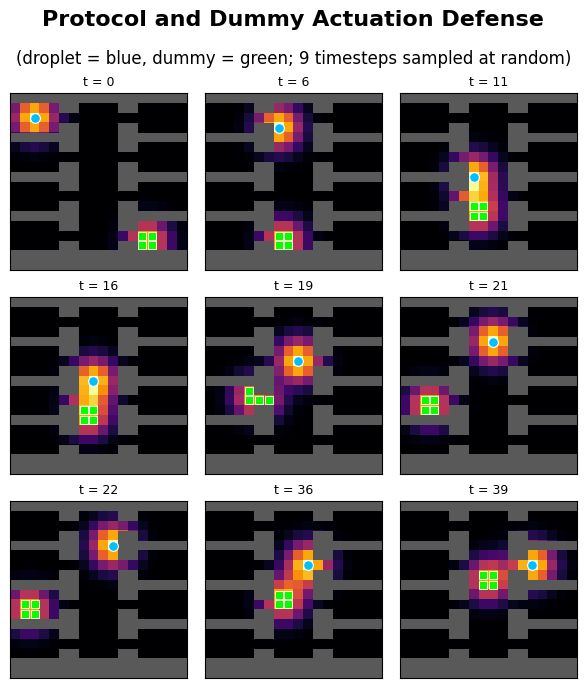

In [37]:
visualize.plot_protocol_sample(protocol, schedule);

## 6. Visualization 

**entropy plots at each timestep for defended and undefended protocol**

**Entropy of undefended protocol**


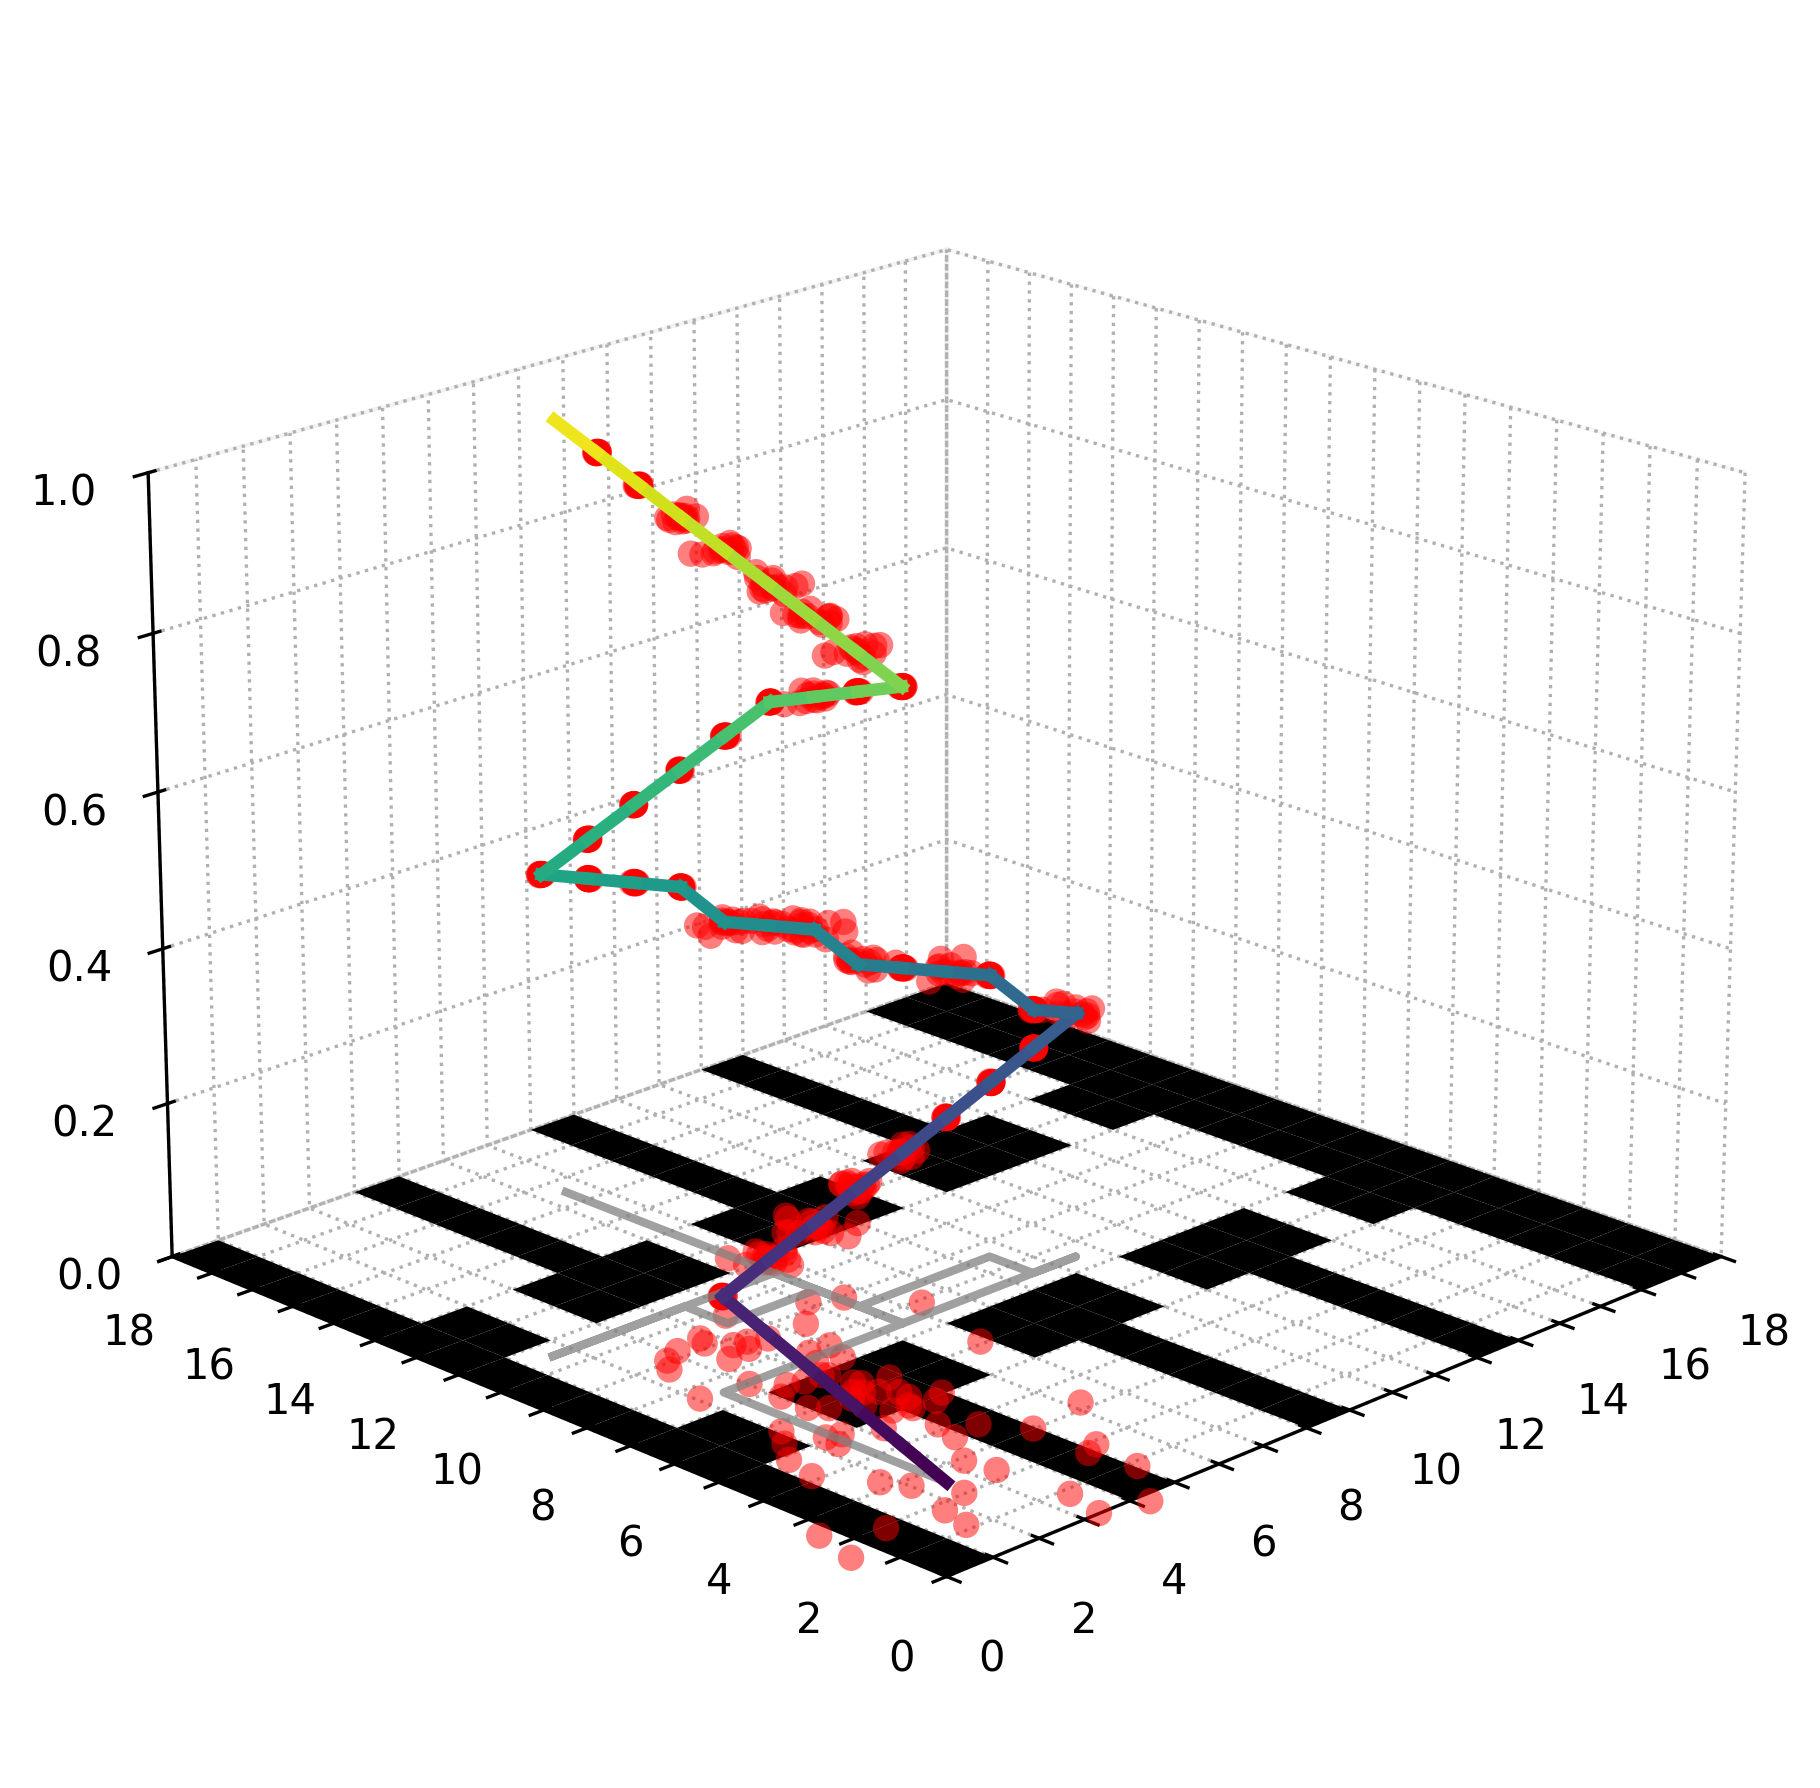

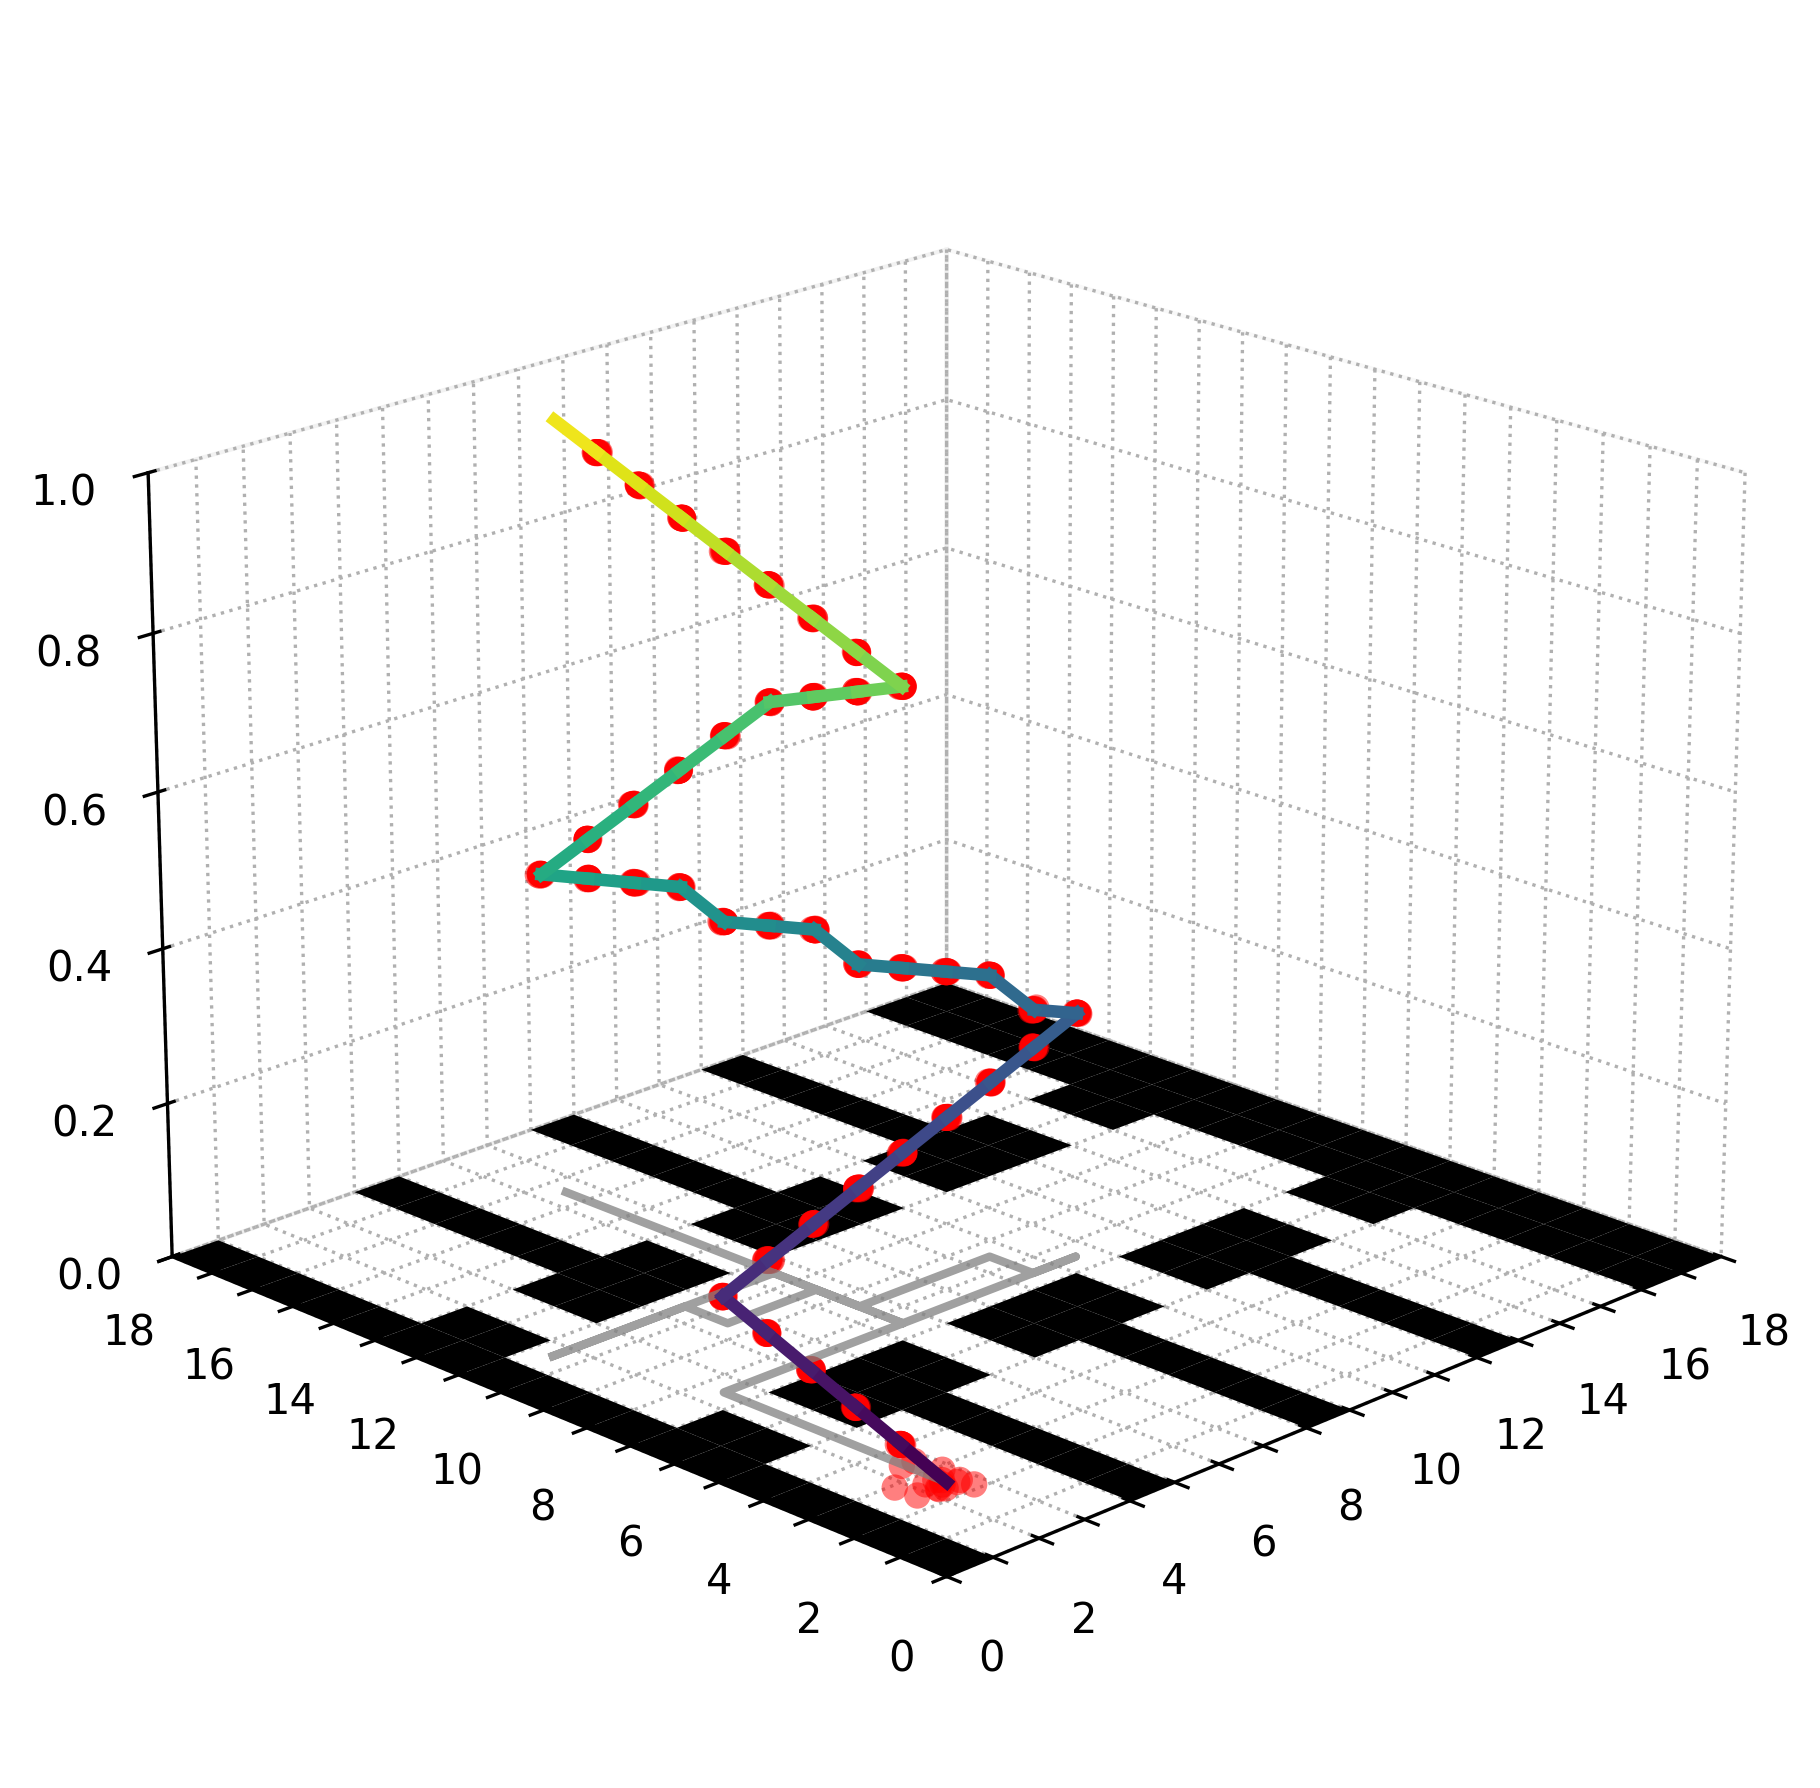

In [38]:
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, undefended_results[1])
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, undefended_results[3])

**Entropy of defended protocol**

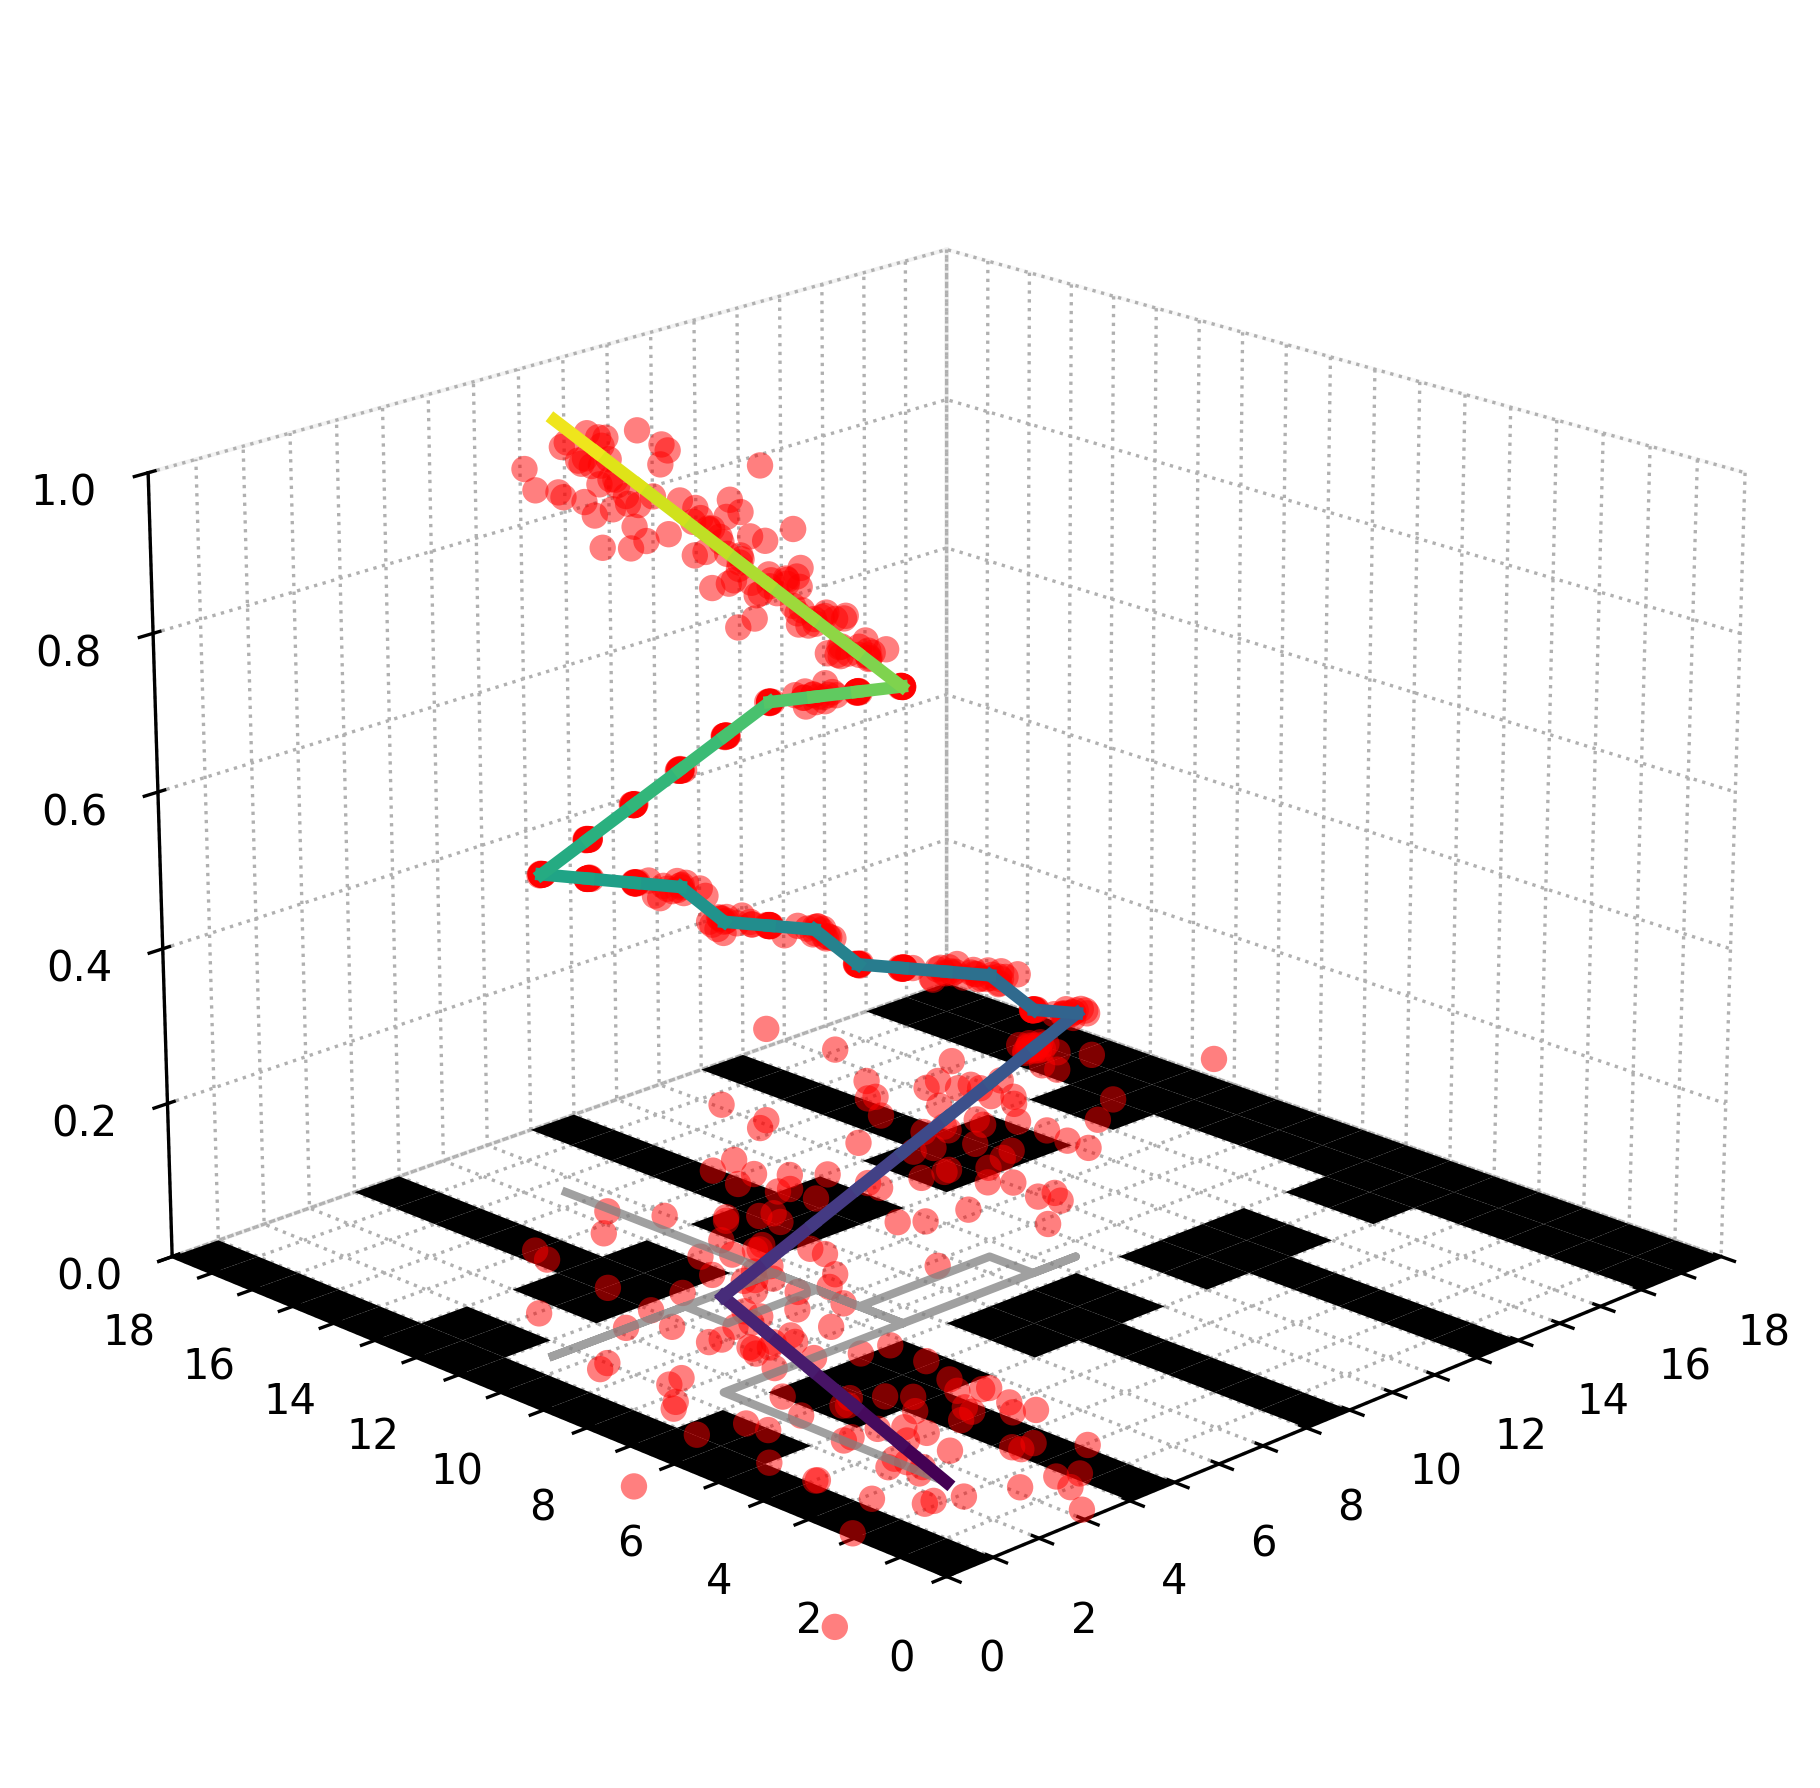

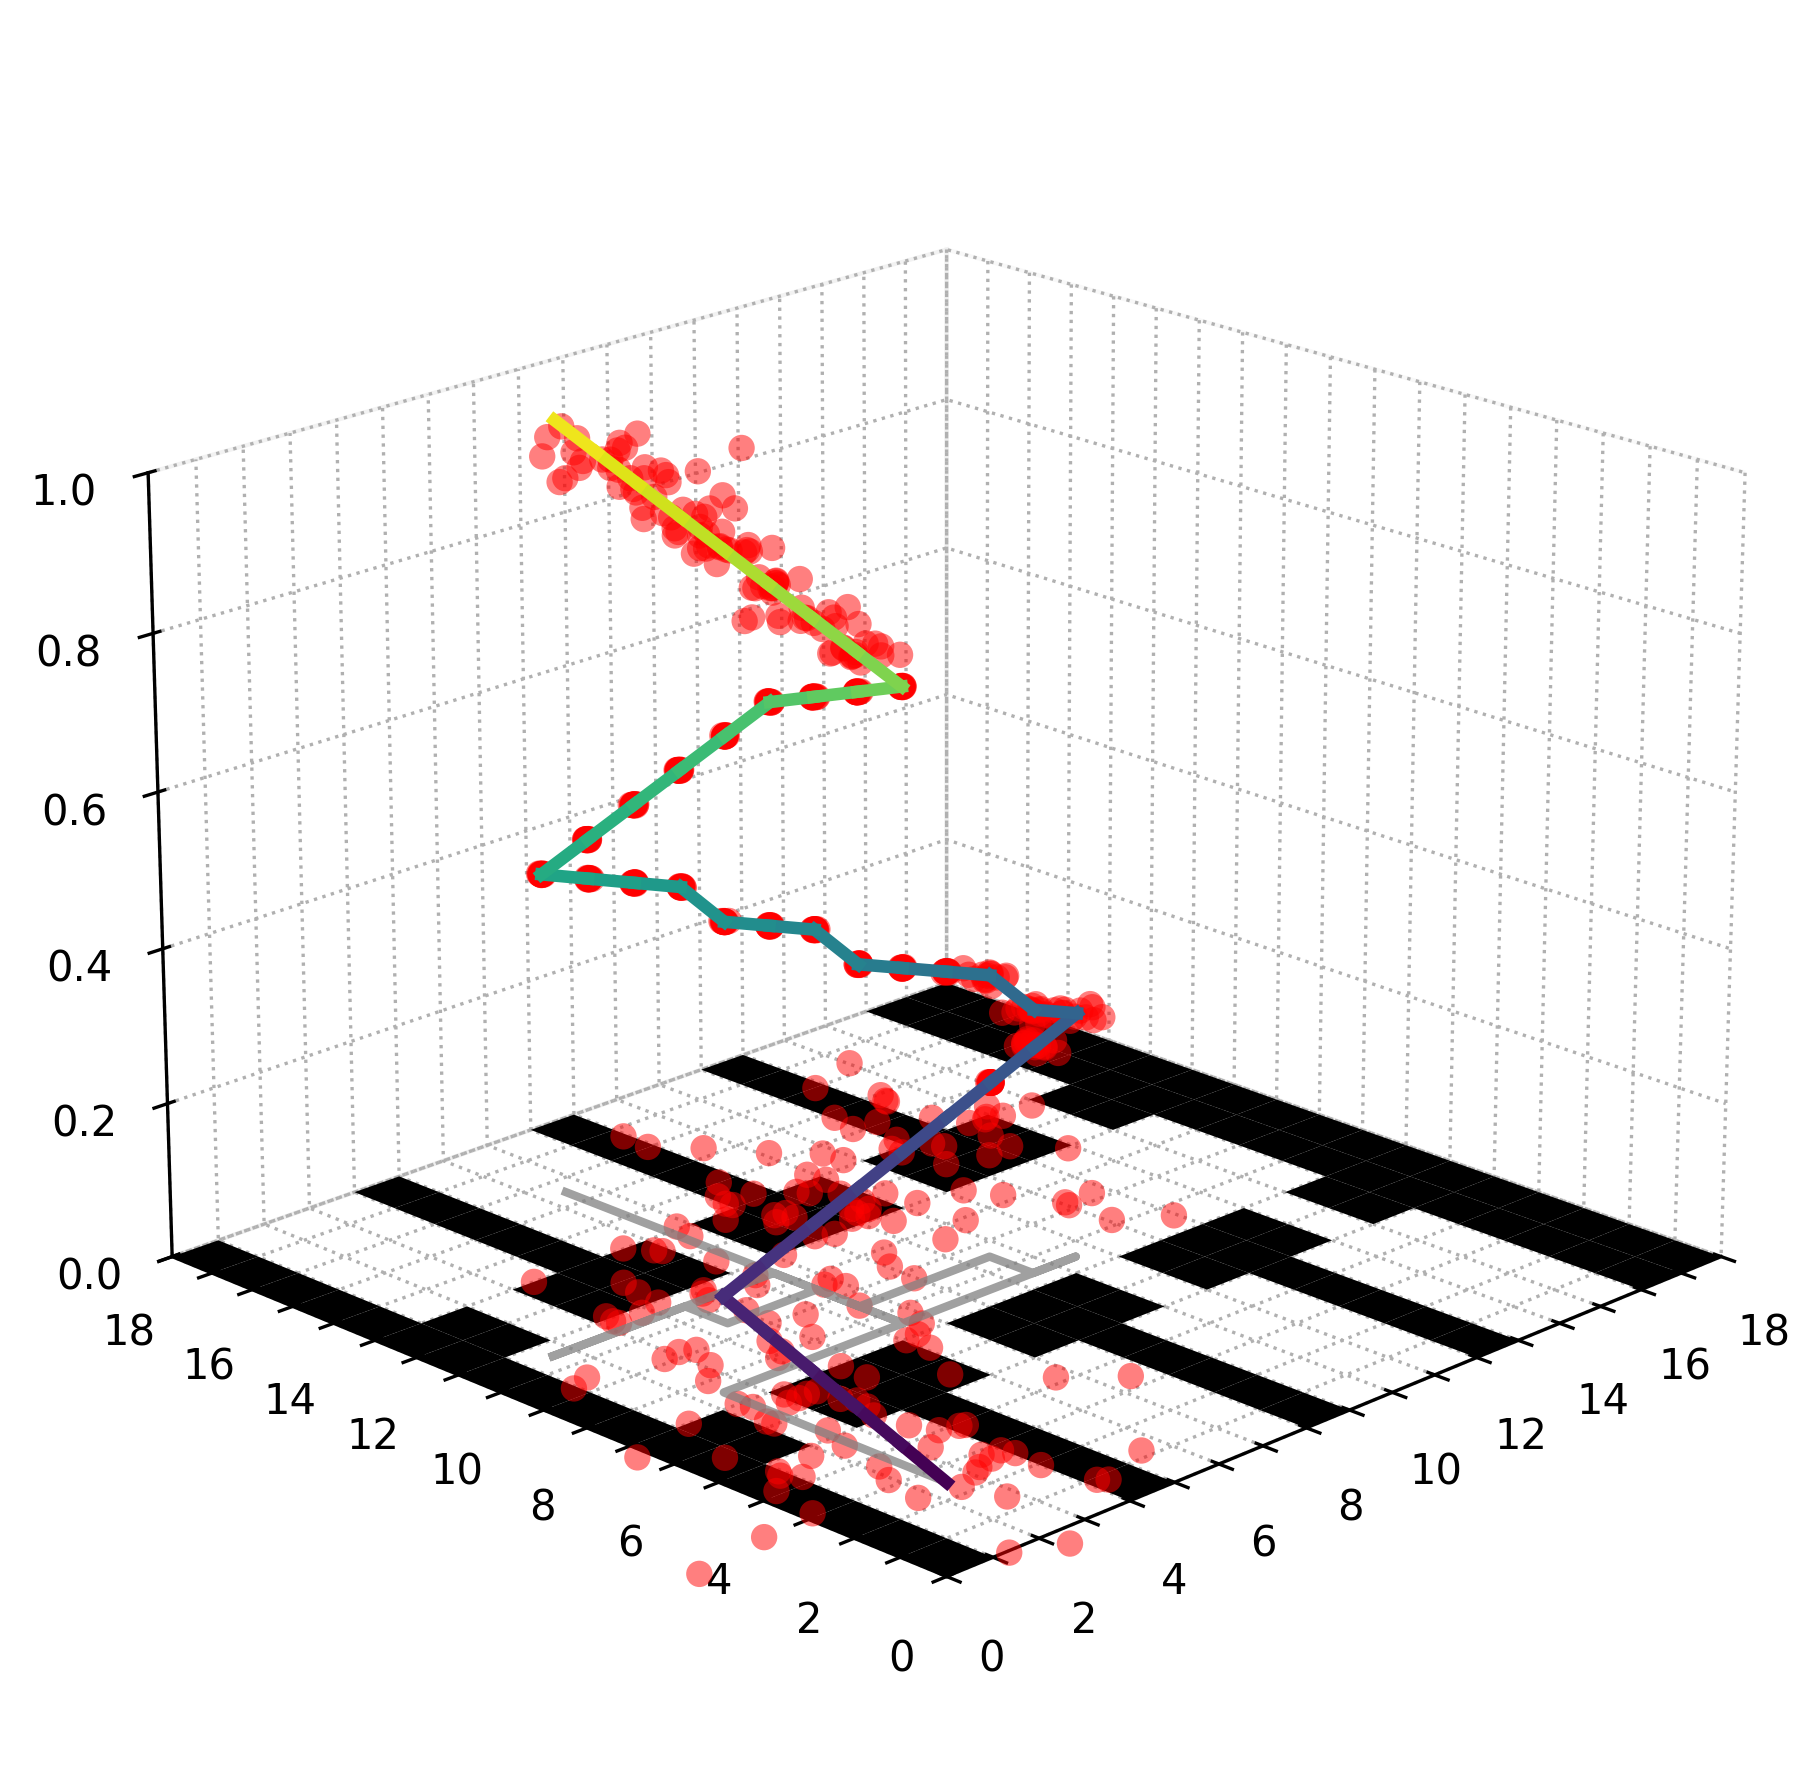

In [39]:
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, results[1])
plot_3d_entropy_path(protocol, config.GRID_SIZE, config.OBSTACLES, results[3])